In [1]:
import numpy as np
import matplotlib.pyplot as plt

$$ x'(t) = \lambda _1 x(t) $$
$$ y'(t) = \lambda _2 y(t) $$

solution: 
$$ x(t) = x_0 exp(\lambda _1 t) $$
$$ y(t) = y_0 exp(\lambda _2 t) $$

Courbes intégrale : $$ y(x)=\frac{y_0}{x_0} |x|^{\frac{\lambda _2}{\lambda _1}} $$

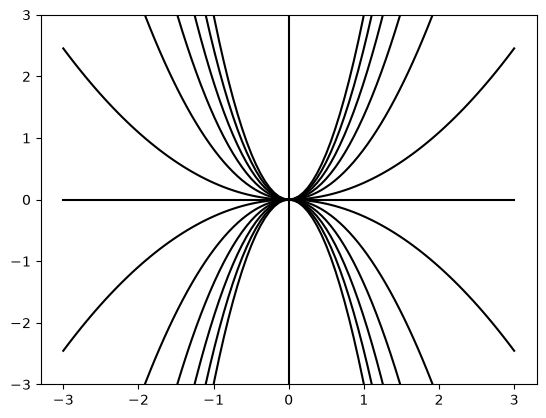

In [2]:
x1 = np.linspace(-3, -0.01, 50)
x2 = np.linspace(0.01, 3, 50)

def y(x, C, Lambda):
    return C*np.abs(x)**(Lambda)

C = np.linspace(-3, 3, 12)

for i in range(12):
    c = C[i]
    Y1 = y(x1, c, 2)
    Y2 = y(x2, c, 2)

    plt.plot(x1, Y1, color="k")
    plt.plot(x2, Y2, color="k")
plt.plot([-3, 3], [0, 0], color="k")
plt.plot([0, 0], [-3, 3], color="k")
plt.ylim(-3, 3)
plt.show()

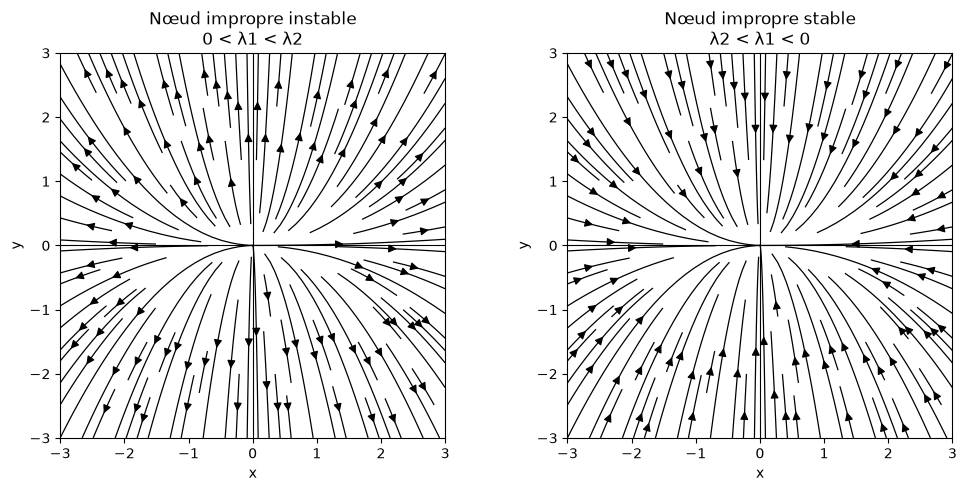

In [3]:
# Création de la grille
x = np.linspace(-3, 3, 30)
y = np.linspace(-3, 3, 30)
X, Y = np.meshgrid(x, y)

# Fonction pour tracer le portrait de phase
def portrait(ax, lambda1, lambda2, titre):

    # Système différentiel
    U = lambda1 * X
    V = lambda2 * Y

    # Champ de vecteurs
    ax.streamplot(
        X, Y, U, V,
        density=1.2,
        color='black',
        linewidth=0.9,
        arrowsize=1.2
    )

    # Axes
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)

    # Mise en forme
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(titre)
    ax.set_aspect('equal')
    ax.grid(False)


# Création des deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Nœud impropre instable
portrait(
    axes[0],
    lambda1=1,
    lambda2=2,
    titre="Nœud impropre instable\n0 < λ1 < λ2"
)

# 2. Nœud impropre stable
portrait(
    axes[1],
    lambda1=-1,
    lambda2=-2,
    titre="Nœud impropre stable\nλ2 < λ1 < 0"
)

# EDO pour la minimisation

on veux minimiser:
$$ min_{(x,y) \in \R^2} f(x,y), ~~~~ \text{avec } f(x,y) = x^2 + 2y^2 +xy -2x -4y$$

On a:
- $f \in C^\infty$
- $f$ strictement convexe
- $f$ coercive

Donc le $f$ admet un unique minimiseur sur $\R^2$.

Alors ce problème peut être résolu en trouvant la limite de la solution de cette edo:
$$ 
\begin{pmatrix}
x'(t)\\
y'(t)
\end{pmatrix} 
= - \nabla f(x,y)
$$

In [4]:
def F(X):
    x,y = X
    return x**2 + 2*y**2 + x*y -2*x -4*y

def gF(X):
    x,y = X
    return np.array([2*x + y -2, 4*y + x - 4])

def Euler2(gF, X0, h, t_max):
    T = t_max//h
    Sx = [] ; Sy = []
    for i in range(int(T)):
        X0 = X0 - h*gF(X0)
        Sx.append(X0[0])
        Sy.append(X0[1])
    return Sx, Sy

X0 = (-6,0)
XX, YY = Euler2(gF, X0, 0.01, 100)

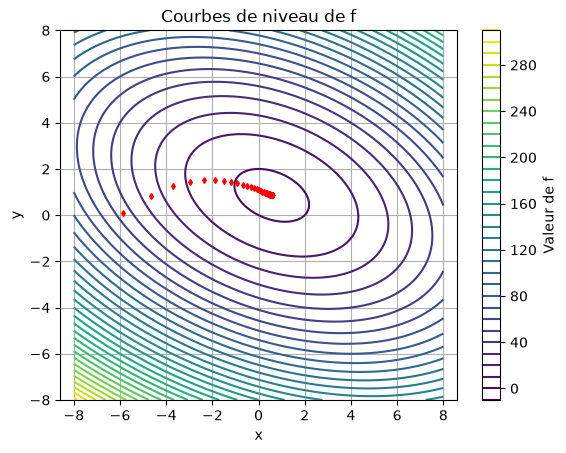

In [5]:
# Création d'une grille de points
x = np.linspace(-8, 8, 200)
y = np.linspace(-8, 8, 200)

X, Y = np.meshgrid(x, y)

# Calcul de f sur la grille
Z = F((X,Y))

# Tracé des courbes de niveau
plt.contour(X, Y, Z, levels=35)

plt.plot(XX[::10], YY[::10], 'd', markersize=3, color='red')

plt.xlabel("x")
plt.ylabel("y")
plt.title("Courbes de niveau de f")
plt.colorbar(label="Valeur de f")
plt.axis("equal")
plt.grid()
plt.show()

In [6]:
# Fonction pour tracer le portrait de phase
def portraitF(ax, titre):

    # Création de la grille
    x = np.linspace(-8, 8, 800)
    y = np.linspace(-8, 8, 800)
    X, Y = np.meshgrid(x, y)

    # Système différentiel
    U = -(2*X + Y - 2)
    V = -(4*Y + X - 4)

    # Champ de vecteurs
    ax.streamplot(
        X, Y, U, V,
        density=1.2,
        color='black',
        linewidth=0.9,
        arrowsize=1.2
    )

    # Axes
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)

    # Mise en forme
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(titre)
    ax.set_aspect('equal')
    ax.grid(False)
    return

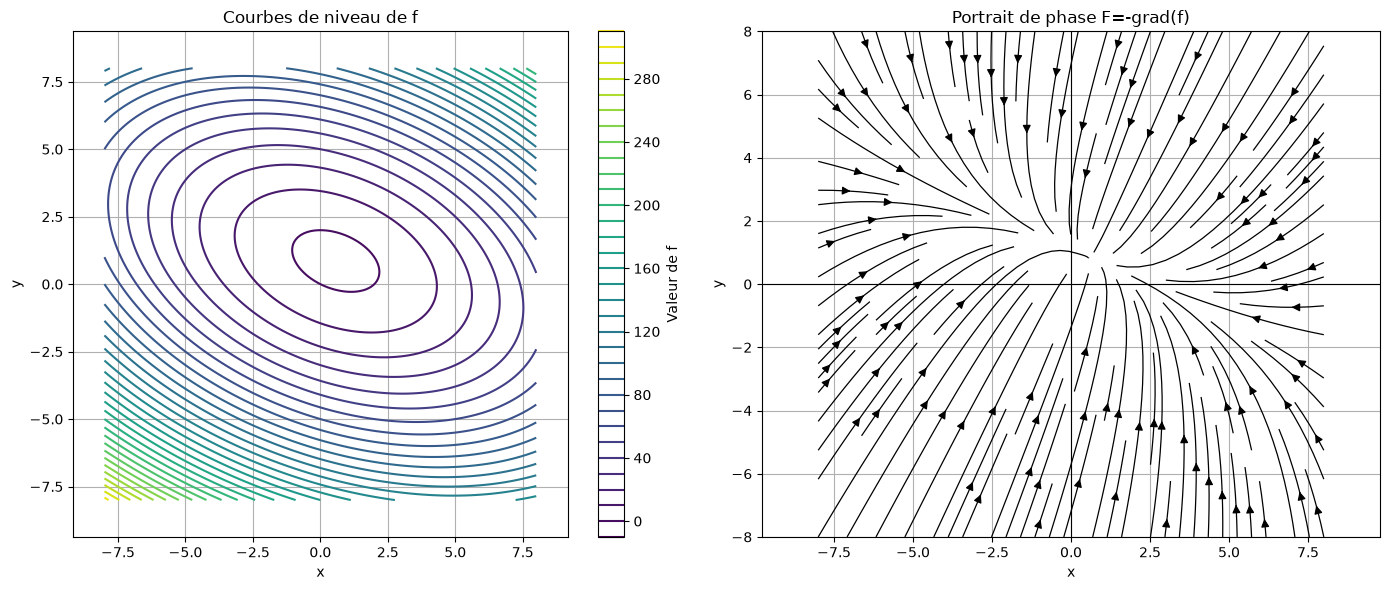

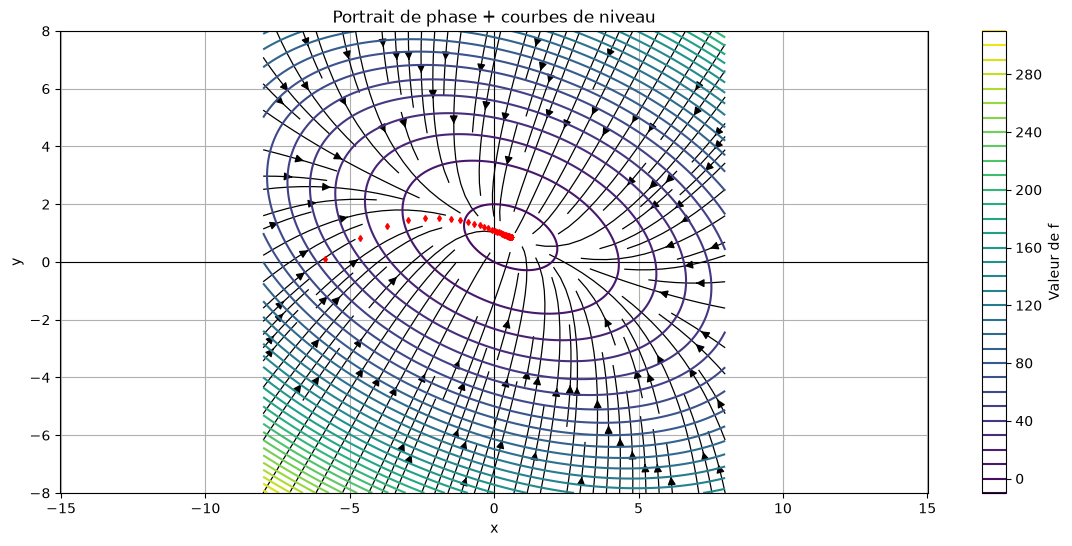

In [7]:
# Création de la grille de points
x = np.linspace(-8, 8, 200)
y = np.linspace(-8, 8, 200)
X, Y = np.meshgrid(x, y)

# Calcul de f sur la grille
Z = F((X, Y))


# Création de deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Graphique 1 : courbes de niveau ---

# Courbes de niveau
contours = axes[0].contour(X, Y, Z, levels=35, cmap="viridis")

axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].axis("equal")
axes[0].grid()
axes[0].set_title("Courbes de niveau de f")
fig.colorbar(contours, ax=axes[0], label="Valeur de f")


# --- Graphique 2 : uniquement le portrait de phase ---

portraitF(axes[1], titre="Portrait de phase F=-grad(f)")

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].axis("equal")
axes[1].grid()

# Affichage
plt.tight_layout()
plt.show()



# Création du graphiques récapitulatif
fig, axes = plt.subplots(1, 1, figsize=(14, 6))


# --- Graphique  : superposition de toutes les fonctions ---

portraitF(axes, titre="Portrait de phase + courbes de niveau")

# Courbes de niveau
contours = axes.contour(X, Y, Z, levels=35, cmap="viridis")

# Points
axes.plot(XX[::10], YY[::10], 'd', markersize=3, color='red')

axes.set_xlabel("x")
axes.set_ylabel("y")
axes.axis("equal")
axes.grid()
fig.colorbar(contours, ax=axes, label="Valeur de f")
plt.show()

On considère le problème:
$$\min_{x\in \R^n} f(x)$$

$\underline{\textbf{Proposition:}}$ Si on suppose que $f$ est coercive, et qu'il existe $\alpha$ et $\beta$ positif tel que:
$$\forall x, \forall \xi \in \R^n:  \beta ||\xi||^2 \ge ~~< D^2f(x)\xi, \xi>~~ \ge \alpha||\xi||^2$$
Alors la solution $x(t)$ du problème de Cauchy:
$$ 
\left\{
\begin{array}{ll}
    \dot{x} = -\nabla f(x) \\
    x(0) = x_0
\end{array}
\right.
$$
converge vers $x^\star$ avec $x^\star$ tel que $f(x^\star) = \min_{x\in \R^n}f(x)$, et de plus la convergence est exponentielle.

$$~~$$
$$~~$$

$\underline{\textbf{Preuve:}}$
Pour comencer, l'hypothèse sur $D^2f$ implique: $f \mapsto \nabla f$ est globalement lipschitzienne:
$$
|\nabla f(x) - \nabla f(y)| = \int^1_0 D^2f(y+\sigma (x-y))d\sigma \cdot (x-y) \leq \beta|x-y|
$$
Donc on a l'existence et l'unicité de la solution $x(t)$ à notre problème de Cauchy.

De plus, on pose $y(t) = x(t) - x^\star$, alors $\dot{y} = -\nabla f(y + x^\star)$. On a ensuite:
$$
\begin{align*}
 &\dot{y}y = -\nabla f(y + x^\star)\cdot y \\
 & = -(\nabla f(y + x^\star) -\nabla f(x^\star))y \\
 &\leq -\alpha|y|^2
\end{align*}
$$

De plus, $\frac{d}{dt}|y|^2 = \frac{d}{dt}(y\cdot y) = 2\dot{y}y $, on a ainsi:

$$
\begin{align*}
 &\frac{1}{2} \frac{d}{dt}|y|^2 + \alpha |y|^2 \leq 0\\
 &\Leftrightarrow \frac{d}{dt}|y|^2 + 2\alpha |y|^2 \leq 0\\
 &\Leftrightarrow \frac{d}{dt}( e^{2\alpha t} |y^2|) \leq 0 \\
 &\Leftrightarrow |y(t)|^2 \leq |y(0)|^2 e^{-2\alpha t} \\
 &\Leftrightarrow |y(t)|^2 \leq |x_0 - x^\star|^2 e^{-2\alpha t}
\end{align*}
$$

Soit $|x(t)-x^\star| \leq |x_0 - x^\star| e^{-\alpha t}$

$$~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~\square$$